# P(k) and CMB lensing emulator accuracy

Validates the lightweight JAX/NPZ `pk_lin`, `pk_nl_boost` and `clpp` emulators against the
bundled held-out fixture in `data/validation_lss_500.h5`. The rows come from the tail of
the full LSS training HDF5 (rows 483,251-483,750), never seen in training since
`train_emulator.py` reads `[:440000]`.

Shows the **raw relative error** `|pred - truth| / |truth|` vs wavenumber, redshift and
multipole. P_NL is the product of the `pk_lin` and `pk_nl_boost` predictions.

In [1]:
from pathlib import Path

import numpy as np
import h5py
import hdf5plugin  # noqa: F401  registers the Zstd decompressor
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})

## Configuration

In [2]:
NTEST = 500  # max rows to read from the validation fixture

# Works whether the notebook is launched from the repo root or notebooks/.
REPO_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA_FILE = REPO_ROOT / 'data' / 'validation_lss_500.h5'

print('data:', DATA_FILE)

data: /cluster/work/refregier/alexree/local_packages/cmb_baryon_emu/data/validation_lss_500.h5


## 1. Load lightweight JAX models + held-out data

In [3]:
from cmb_baryon_emu import JaxNpzModel

pk_lin = JaxNpzModel.from_package('pk_lin')
pk_boost = JaxNpzModel.from_package('pk_nl_boost')
clpp = JaxNpzModel.from_package('clpp')
for name, m in [('pk_lin', pk_lin), ('pk_nl_boost', pk_boost), ('clpp', clpp)]:
    print(f'{name:12s} parameter_names: {m.parameter_names}')

with h5py.File(DATA_FILE, 'r') as f:
    n_test = min(NTEST, f['params'].shape[0])
    raw_params = f['params'][-n_test:]
    truth = {key: f[key][-n_test:] for key in ('pk_lin', 'pk_nl', 'clpp')}
    k, z, ell = f['pk_k'][:], f['pk_z'][:], f['ell'][:]

params = {name: raw_params[name] for name in raw_params.dtype.names}
assert np.allclose(k, pk_lin.pk_k) and np.allclose(z, pk_lin.pk_z)

print('test samples:', n_test)
print(f'P(k) grid: {len(z)} z ({z[0]:.1f}..{z[-1]:.1f}) x {len(k)} k ({k[0]:.0e}..{k[-1]:.0f} h/Mpc)')
print(f'C_L^phiphi: L = {ell[0]}..{ell[-1]}')

pk_lin       parameter_names: ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h']
pk_nl_boost  parameter_names: ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h']
clpp         parameter_names: ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'h', 'log10Mc', 'Theta_co', 'mu', 'delta', 'eta', 'deta', 'Nstar', 'fb']
test samples: 500
P(k) grid: 31 z (0.0..3.0) x 329 k (1e-05..50 h/Mpc)
C_L^phiphi: L = 2..3000


In [4]:
pred = {'pk_lin': pk_lin.predict_pk(params)}
pred['pk_nl'] = pred['pk_lin'] * pk_boost.predict_pk(params)
pred['clpp'] = clpp.predict(params)

rel_err = {key: np.abs(pred[key] - truth[key]) / np.abs(truth[key]) for key in pred}
for key in pred:
    print(f'{key:7s} pred: {pred[key].shape}  truth: {truth[key].shape}')

pk_lin  pred: (500, 31, 329)  truth: (500, 31, 329)
pk_nl   pred: (500, 31, 329)  truth: (500, 31, 329)
clpp    pred: (500, 2999)  truth: (500, 2999)


## 2. Linear P(k): raw relative error vs k

Percentiles over all samples and all 31 redshifts.

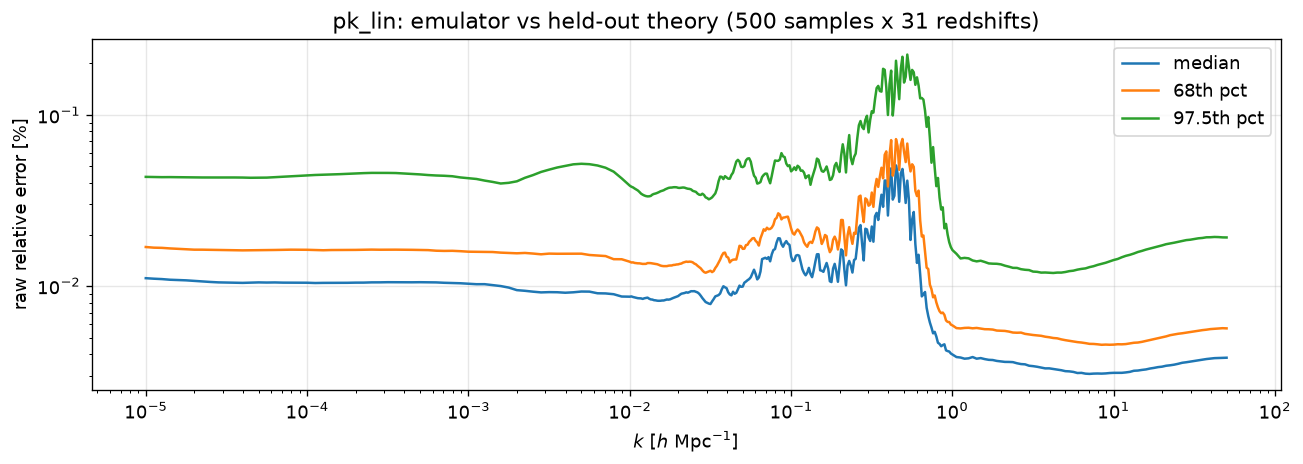

median rel err: 0.0085%   97.5th pct: 0.0665%


In [5]:
err = rel_err['pk_lin'].reshape(-1, len(k))
p50, p68, p975 = np.percentile(err, [50, 68, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(k, 100 * p50, label='median')
ax.plot(k, 100 * p68, label='68th pct')
ax.plot(k, 100 * p975, label='97.5th pct')
ax.set_xlabel(r'$k$ [$h$ Mpc$^{-1}$]')
ax.set_ylabel('raw relative error [%]')
ax.set_title(f'pk_lin: emulator vs held-out theory ({n_test} samples x {len(z)} redshifts)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'median rel err: {100*np.median(err):.4f}%   97.5th pct: {100*np.percentile(err, 97.5):.4f}%')

## 3. Nonlinear P(k) = pk_lin x pk_nl_boost: raw relative error vs k

Compared against the HMcode-2020 P_NL in the fixture, so this includes the errors of
both models.

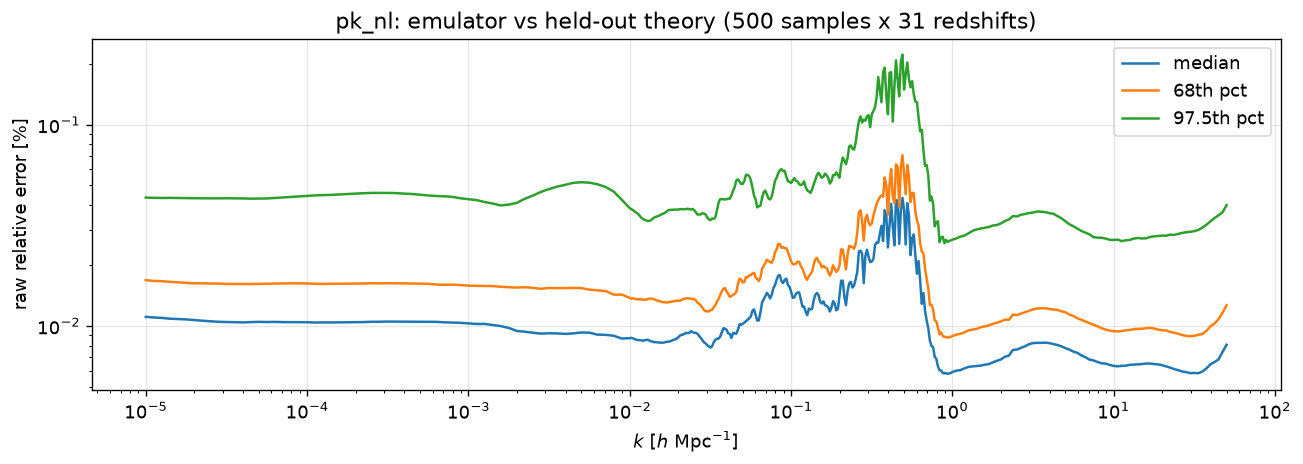

median rel err: 0.0102%   97.5th pct: 0.0650%


In [6]:
err = rel_err['pk_nl'].reshape(-1, len(k))
p50, p68, p975 = np.percentile(err, [50, 68, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(k, 100 * p50, label='median')
ax.plot(k, 100 * p68, label='68th pct')
ax.plot(k, 100 * p975, label='97.5th pct')
ax.set_xlabel(r'$k$ [$h$ Mpc$^{-1}$]')
ax.set_ylabel('raw relative error [%]')
ax.set_title(f'pk_nl: emulator vs held-out theory ({n_test} samples x {len(z)} redshifts)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'median rel err: {100*np.median(err):.4f}%   97.5th pct: {100*np.percentile(err, 97.5):.4f}%')

## 4. P(k): 97.5th percentile error vs redshift

Percentiles over all samples and all k.

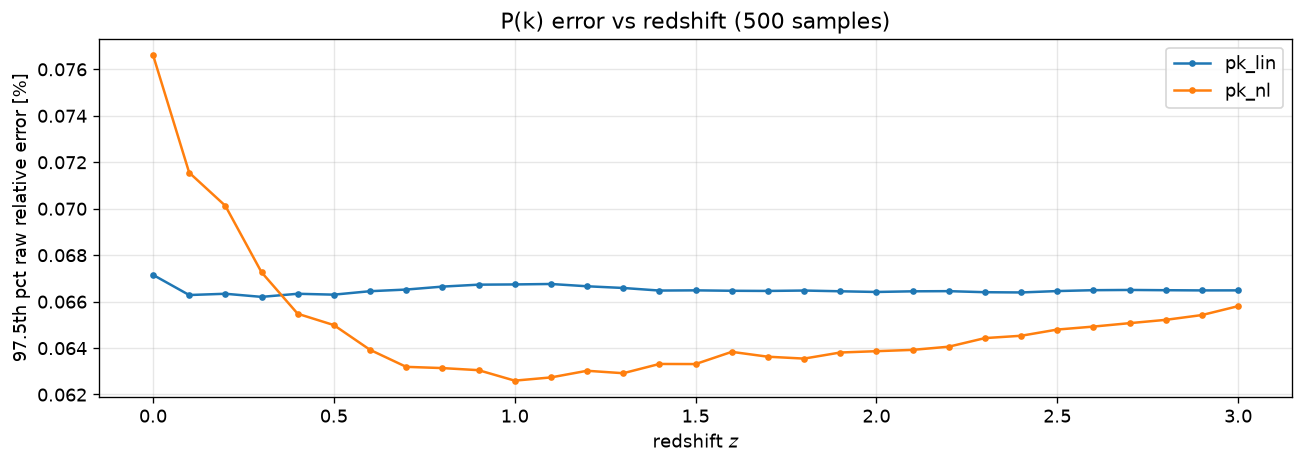

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
for key in ('pk_lin', 'pk_nl'):
    err_z = np.moveaxis(rel_err[key], 1, 0).reshape(len(z), -1)
    ax.plot(z, 100 * np.percentile(err_z, 97.5, axis=1), marker='o', ms=3, label=key)
ax.set_xlabel('redshift $z$')
ax.set_ylabel('97.5th pct raw relative error [%]')
ax.set_title(f'P(k) error vs redshift ({n_test} samples)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. CMB lensing potential $C_L^{\phi\phi}$ with baryons: raw relative error vs L

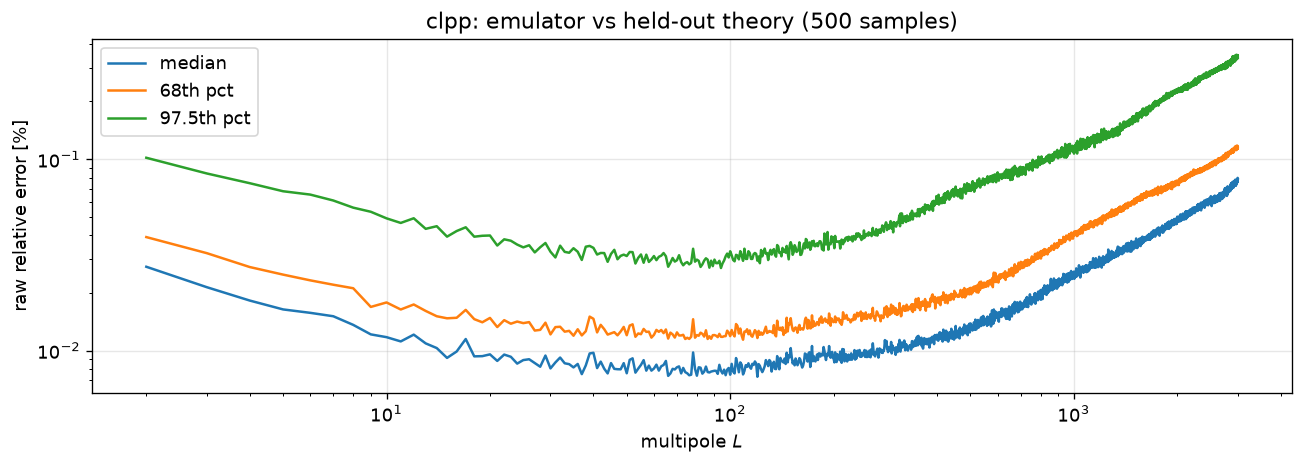

median rel err: 0.0298%   97.5th pct: 0.2207%


In [8]:
err = rel_err['clpp']
p50, p68, p975 = np.percentile(err, [50, 68, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ell, 100 * p50, label='median')
ax.plot(ell, 100 * p68, label='68th pct')
ax.plot(ell, 100 * p975, label='97.5th pct')
ax.set_xlabel(r'multipole $L$')
ax.set_ylabel('raw relative error [%]')
ax.set_title(f'clpp: emulator vs held-out theory ({n_test} samples)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'median rel err: {100*np.median(err):.4f}%   97.5th pct: {100*np.percentile(err, 97.5):.4f}%')

## Summary

In [9]:
for key in ('pk_lin', 'pk_nl', 'clpp'):
    err = rel_err[key]
    print(f'{key:7s} median {100*np.median(err):.4f}%   97.5th pct {100*np.percentile(err, 97.5):.4f}%   '
          f'99th pct {100*np.percentile(err, 99):.4f}%   max {100*err.max():.3f}%')

pk_lin  median 0.0085%   97.5th pct 0.0665%   99th pct 0.1020%   max 0.572%


pk_nl   median 0.0102%   97.5th pct 0.0650%   99th pct 0.0988%   max 0.569%
clpp    median 0.0298%   97.5th pct 0.2207%   99th pct 0.2848%   max 0.702%
